### 实验1 神经网络原理与实现 (神经网络实现手写数字识别)
（本实验以及后续实验，均使用PyTorch框架）
#### 一、基本实现过程
##### 1.1 基本设置
（1）导入torch等第三方库

In [326]:
import random
import numpy as np
import pandas as pd

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset # 数据集组织，以便后面batch划分
import torch.optim as optim # 优化器

（2）设置图表显示

In [327]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker  # 导入刻度格式化模块
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']  # 支持中文字体
plt.rcParams['figure.dpi'] = 300   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

（3）设置固定随机种子，以便复现

In [328]:
# 设置随机种子（不含对batch划分的设置）
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

##### 1.2 数据导入与预处理
（1）导入数据集并观察形状

In [329]:
# 观察数据集都有哪些文件
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [330]:
# 导入数据，并观察数据形状
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集特征形状: {x_train.shape}")
print(f"训练集标签形状: {y_train.shape}")
print(f"测试集特征形状: {x_test.shape}")
print(f"测试集标签形状: {y_test.shape}")

训练集特征形状: (60000, 28, 28)
训练集标签形状: (60000,)
测试集特征形状: (10000, 28, 28)
测试集标签形状: (10000,)


（2）数据形状转换与归一化

In [331]:
# 将单条 二维标签数据 转变为 一维数据
x_train = x_train.reshape((60000, 28 * 28))
x_test = x_test.reshape((10000, 28 * 28))
print(f"训练集特征形状: {x_train.shape}")
print(f"测试集特征形状: {x_test.shape}")

# 数据范围仅[0, 255]，故除以255即可归一化
x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

# 另外，torch框架下，无需对无序类别标签作one-hot处理

训练集特征形状: (60000, 784)
测试集特征形状: (10000, 784)


（3）转换后的数据，转变为torch的张量

In [332]:
# 将特征、标签等数据，转换为torch中的张量
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long) # 无序类别标签，类型必须是torch.long
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

##### 1.3 网络结构定义与模型训练

Baseline参数汇总：
| 参数 | 值 |
| :---: | :---: |
| 输入层 | 28*28=784 |
| 隐藏层 | 512 |
| 输出层 | 10 |
| 激活函数 | relu |
| dropout | 不设置 |
| epoch | 15 |
| batch | 128 |
| 学习率 | 0.001 |
| 优化器 | RMSprop |
| loss函数 | 交叉熵损失 |

（1）网络结构定义

In [333]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）创建model对象，设置loss函数与优化器

In [334]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

（3）训练模型，并评估每epoch的结果

In [335]:
# 训练模型，并在每轮epoch后，针对训练数据评估模型
def train_model(model, epochs, batch):
    # 全数据集分batch
    g = torch.Generator()
    g.manual_seed(42) # 为了可复现，为batch划分也设置固定随机种子
    
    train_dataset = TensorDataset(x_train_tensor, y_train_tensor) # 特征与标签，一起构造成torch张量数据集
    train_dataloader = DataLoader(train_dataset, batch_size=batch, shuffle=True, generator=g) # 将数据集组织成 以batch加载 的形式
    
    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0  # 记录每个epoch的总损失
        train_num = 0   # 记录训练集的总样本数

        model.train() # 设置为训练模式
        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad() # 梯度清零
            preds_y = model(batch_x) # 前向传播
            loss_train = criterion(preds_y, batch_y) # 计算损失
            loss_train.backward() # 反向传播（自动求导 并 累加梯度）
            optimizer.step() # 根据求导计算出的 梯度，更新模型参数

            train_total_loss_sum += loss_train.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            train_num += batch_y.size(0)

        train_correct = 0
        
        model.eval() # 设置为评估模式
        with torch.no_grad(): # 关闭梯度计算，节省内存
            for batch_x, batch_y in train_dataloader:
                train_preds = model(batch_x) # 前向传播                
                predicted_classes = torch.argmax(train_preds, dim=1) # 将概率最大的标签值，作为预测结果
                train_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
        
        loss_result.append([f"{epoch + 1}/{epochs}", train_total_loss_sum / train_num, train_correct / train_num]) # 记录每epoch的loss与Acc
        # print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {train_total_loss_sum / train_num:.4f}, 训练集Acc: {train_correct / train_num * 100:.2f}%  ({train_correct}/{train_num})")

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

In [336]:
train_result_df = train_model(model, epochs=15, batch = 128)
train_result_df.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.255084,96.35%
2/15,0.107345,97.80%
3/15,0.070417,98.49%
4/15,0.050758,99.04%
5/15,0.036980,98.62%
6/15,0.027315,99.55%
7/15,0.020776,99.57%
8/15,0.016031,99.77%
9/15,0.011518,99.80%
10/15,0.009150,99.85%


（4）绘制Baseline的loss与Acc曲线，查看收敛情况

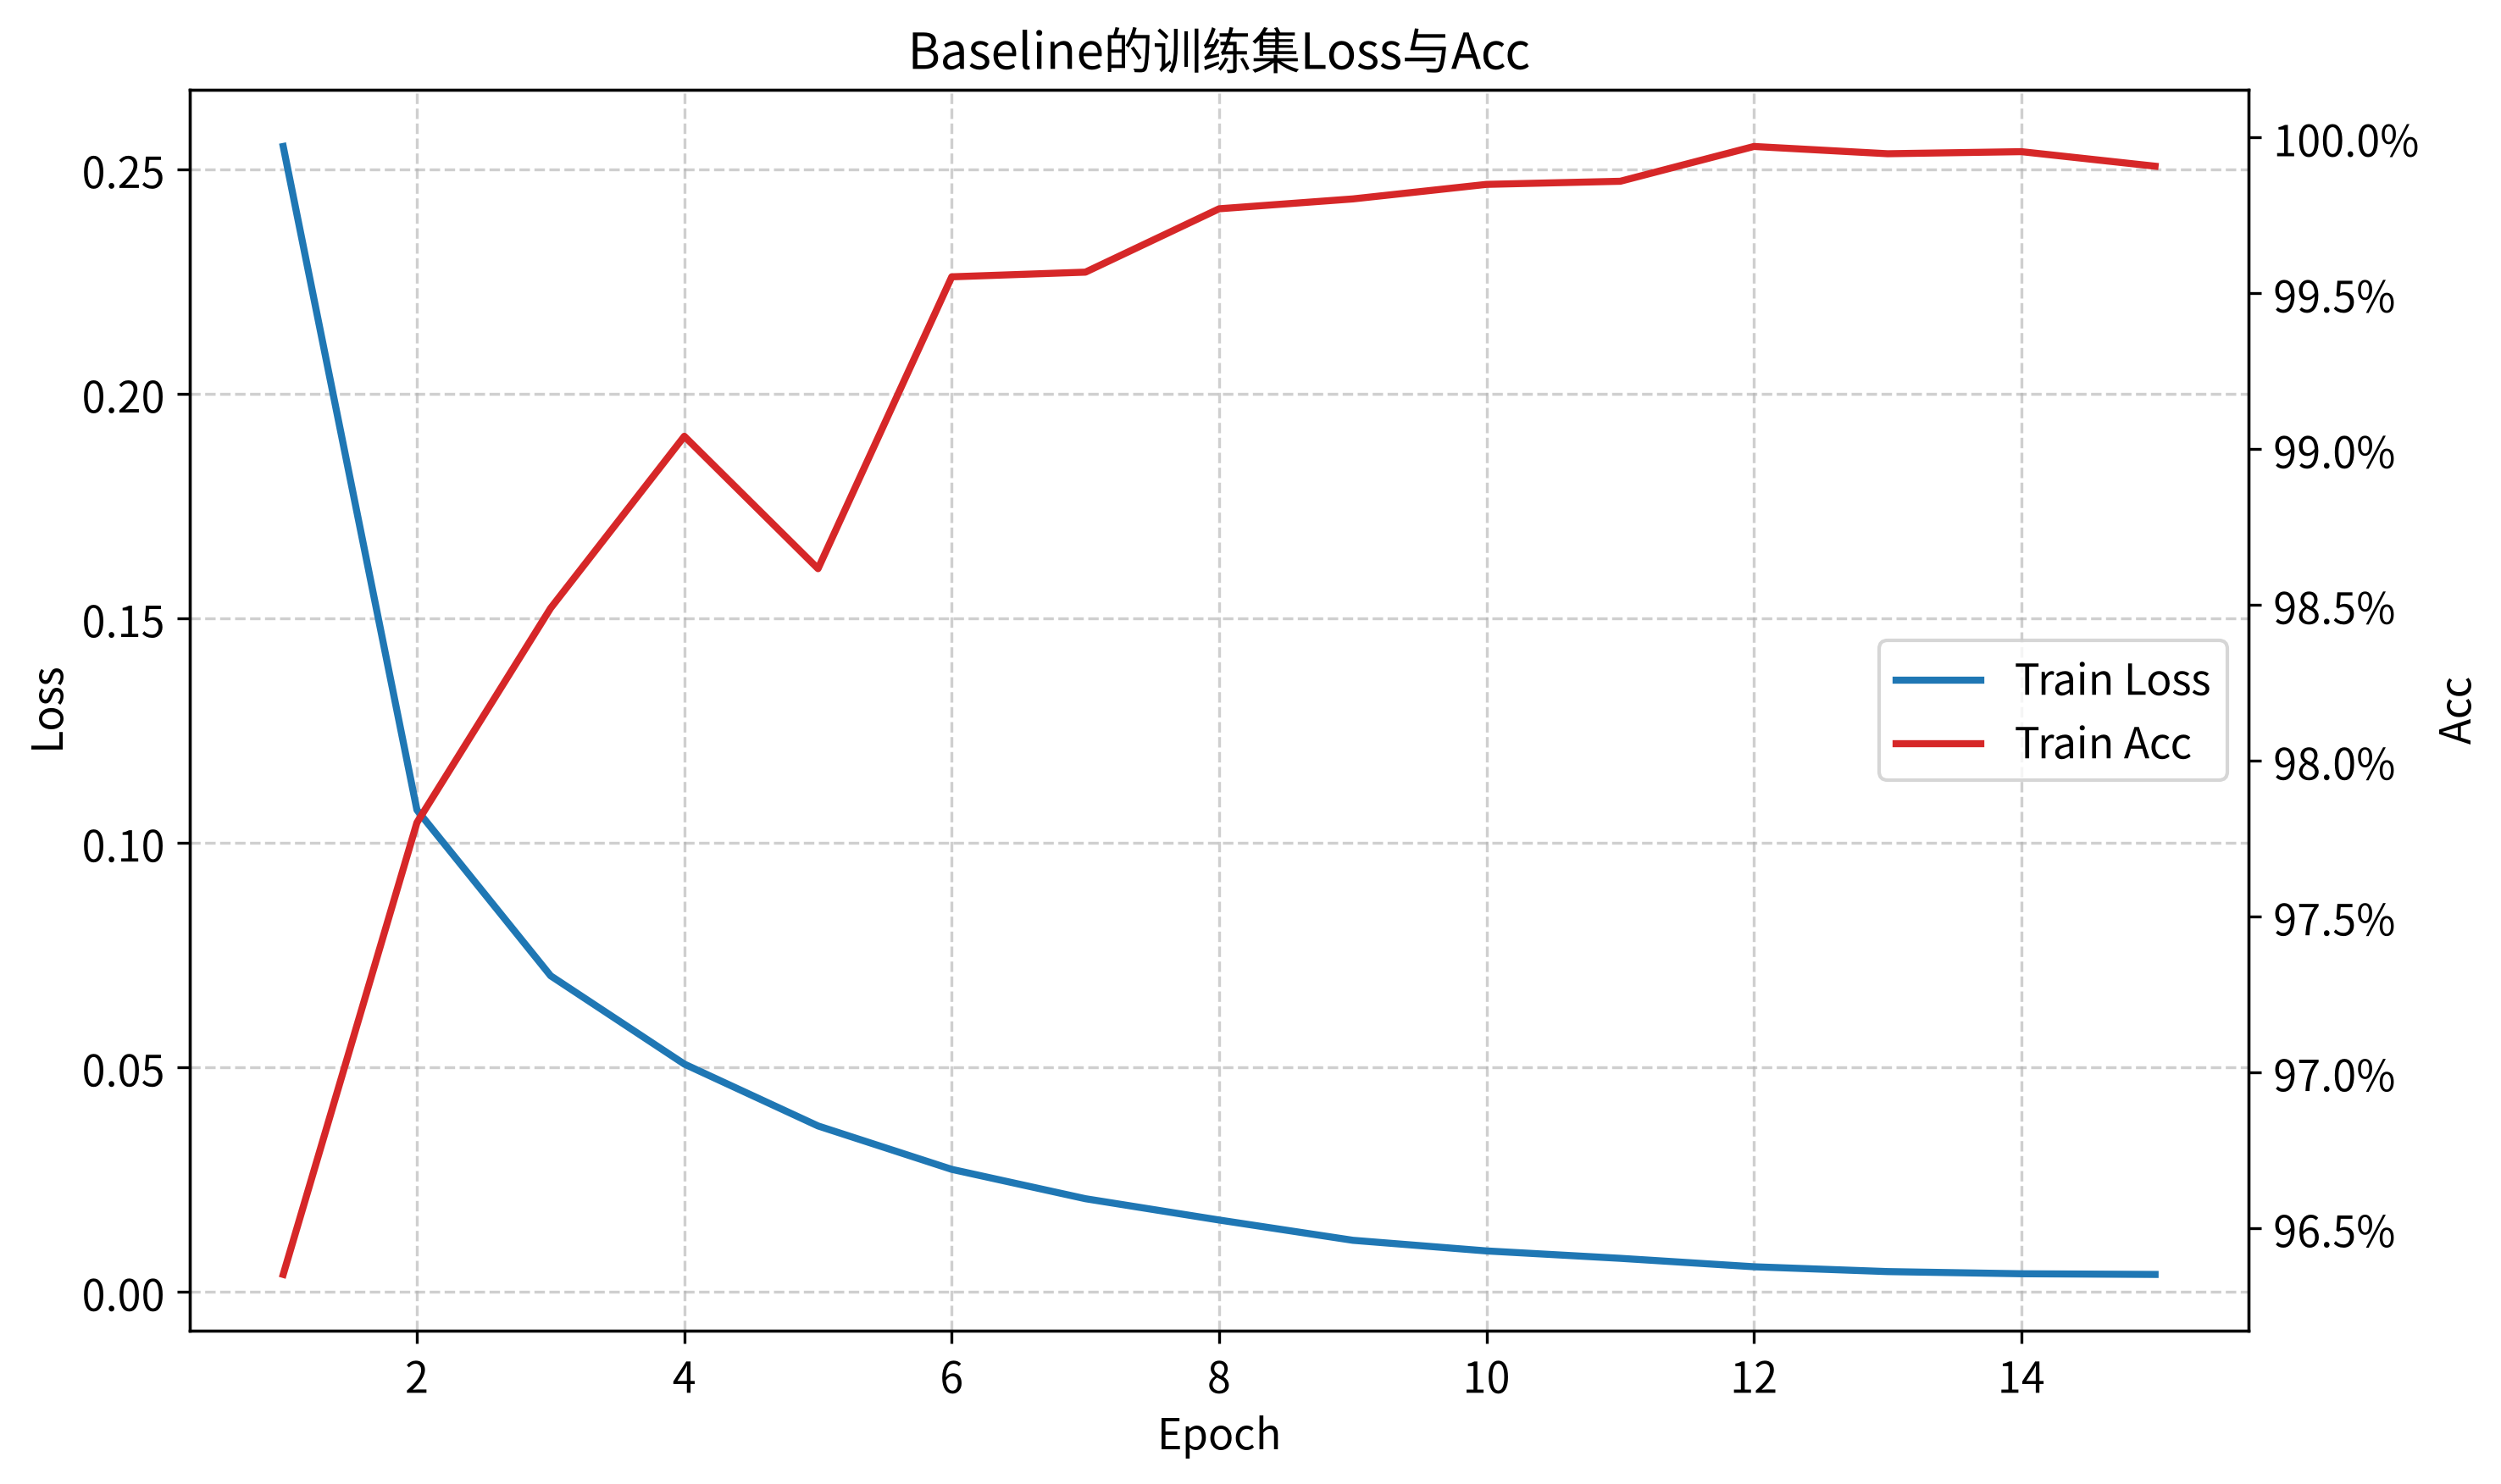

In [337]:
# 从结果列表中提取 loss 和 acc 数据
losses = train_result_df['Loss']
accs = train_result_df['Acc']
epochs = range(1, len(losses) + 1)

# 初始化画布
fig, ax1 = plt.subplots(figsize=(10, 6)) # ax1 作为左侧主坐标轴

# 绘制左侧Loss（蓝线）
color_loss = 'tab:blue'
line1 = ax1.plot(epochs, losses, label='Train Loss', color=color_loss, linewidth=2)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Loss', fontsize=12)
ax1.tick_params(axis='y') # 刻度线颜色与线条一致
ax1.grid(True, linestyle='--', alpha=0.6) # 加网格

# 绘制右侧Acc（红线）
ax2 = ax1.twinx()  
color_acc = 'tab:red'
line2 = ax2.plot(epochs, accs, label='Train Acc', color=color_acc, linewidth=2)
ax2.set_ylabel('Acc', fontsize=12)
ax2.tick_params(axis='y')

ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1)) # 将Acc轴格式化为百分比

# 合并图例
lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='center right', fontsize=12)

# 设置标题并显示
plt.title('Baseline的训练集Loss与Acc', fontsize=14)
plt.tight_layout()
plt.show()

In [338]:
# 在测试集上评估模型并预测
def evaluate_model(model, batch):
    model.eval() # 将模型切换到测试状态
    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    # 同样分batch进行测试
    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad(): # 关闭梯度计算，节省内存
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x) # 前向传播
            loss = criterion(test_preds, batch_y) # 计算单batch的平均loss
            test_total_loss_sum += loss.item() * batch_y.size(0) # 为便于最后计算总平均loss，通过乘以batch样本数，加和单batch下的loss总和
            
            predicted_classes = torch.argmax(test_preds, dim=1) # 将概率最大的标签值，作为预测结果
            test_correct += (predicted_classes == batch_y).sum().item() # 统计预测正确的样本数
            test_num += batch_y.size(0) # 统计测试集总样本数

            test_result += predicted_classes.tolist() # 追加预测结果（argmax 概率）
            test_probs += torch.softmax(test_preds, dim=1).tolist() # 追加每个数字的预测概率

    avg_test_loss = test_total_loss_sum / test_num  # 计算总平均loss
    accuracy = test_correct / test_num    # 计算Acc

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    # 预测结果
    result_df = pd.DataFrame(test_result, columns=['Predict'])
    # 预测该数字为0-9的原始概率
    prob_columns = [f'Prob_{i}' for i in range(10)] 
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    # 合并成一个df
    result_df = pd.concat([result_df, prob_df], axis=1)
    
    return result_df

In [339]:
test_result = evaluate_model(model, batch=128)
test_result.round(4)

测试集loss: 0.0722
测试集Acc: 98.34%  (9834/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9995,0.0,0.0,0.0,0.0,0.0005
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


#### 二、参数调整与对比
##### 2.1 隐藏层数

（1）修改网络结构如下，将隐藏层数调整为2与3，并定义新增隐藏层的结构一致

In [340]:
# 2个隐藏层的网络结构
class MultipleHiddenNet_2(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层1 512
        self.fc2 = nn.Linear(512, 512) # 隐藏层1 512 -> 隐藏层2 512
        self.out = nn.Linear(512, 10) # 隐藏层2 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.out(x)  # 直接输出线性结果
        return x

# 3个隐藏层的网络结构
class MultipleHiddenNet_3(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层1 512
        self.fc2 = nn.Linear(512, 512) # 隐藏层1 512 -> 隐藏层2 512
        self.fc3 = nn.Linear(512, 512) # 隐藏层2 512 -> 隐藏层3 512
        self.out = nn.Linear(512, 10) # 隐藏层3 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）2个隐藏层结构的训练与评估

In [341]:
model = MultipleHiddenNet_2() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.229911,97.17%
2/15,0.083382,98.37%
3/15,0.055119,98.36%
4/15,0.040226,99.08%
5/15,0.027326,99.22%
6/15,0.022468,99.56%
7/15,0.018806,99.70%
8/15,0.015082,99.61%
9/15,0.014777,99.73%
10/15,0.011774,99.70%


In [342]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0918
测试集Acc: 98.30%  (9830/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（3）3个隐藏层结构的训练与评估

In [343]:
model = MultipleHiddenNet_3() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.259270,97.02%
2/15,0.089188,98.16%
3/15,0.060405,98.58%
4/15,0.046541,99.16%
5/15,0.036025,98.70%
6/15,0.028797,99.50%
7/15,0.024103,99.41%
8/15,0.020299,99.47%
9/15,0.021357,99.73%
10/15,0.016610,99.55%


In [344]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.1285
测试集Acc: 98.09%  (9809/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（4）对比结果可视化

In [345]:
# 不同模型训练结果对比可视化（后面的实验将复用该函数）
def plot_multiple_models_train_result(results_dict, title):
    # 初始化画布：1行2列，共享X轴
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6), sharex=True)
    
    # 定义不同模型线条的颜色
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    
    # 遍历字典，绘制每个模型的曲线
    for i, (model_name, df) in enumerate(results_dict.items()):
        color = colors[i % len(colors)] # 循环使用颜色
        
        # 提取数据
        epochs = range(1, len(df) + 1)
        losses = df['Loss']
        accs = df['Acc']
        
        ax1.plot(epochs, losses, label=model_name, color=color, linewidth=2) # 左图Loss
        ax2.plot(epochs, accs, label=model_name, color=color, linewidth=2) # 右图Acc

    # 设置左图Loss
    ax1.set_title('训练集 Loss', fontsize=14)
    ax1.set_xlabel('Epoch', fontsize=12)
    ax1.set_ylabel('Loss', fontsize=12)
    ax1.grid(True, linestyle='--', alpha=0.6)
    ax1.legend(fontsize=12) # 左侧图例

    # 设置右图Acc
    ax2.set_title('训练集 Acc', fontsize=14)
    ax2.set_xlabel('Epoch', fontsize=12)
    ax2.set_ylabel('Acc', fontsize=12)
    ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.legend(fontsize=12) # 右侧图例
    
    # 右图纵轴格式化为百分比
    ax2.yaxis.set_major_formatter(ticker.PercentFormatter(xmax=1.0, decimals=1))

    # 全局设置与显示
    fig.suptitle(title, fontsize=16) # 总标题
    plt.tight_layout()
    plt.show()

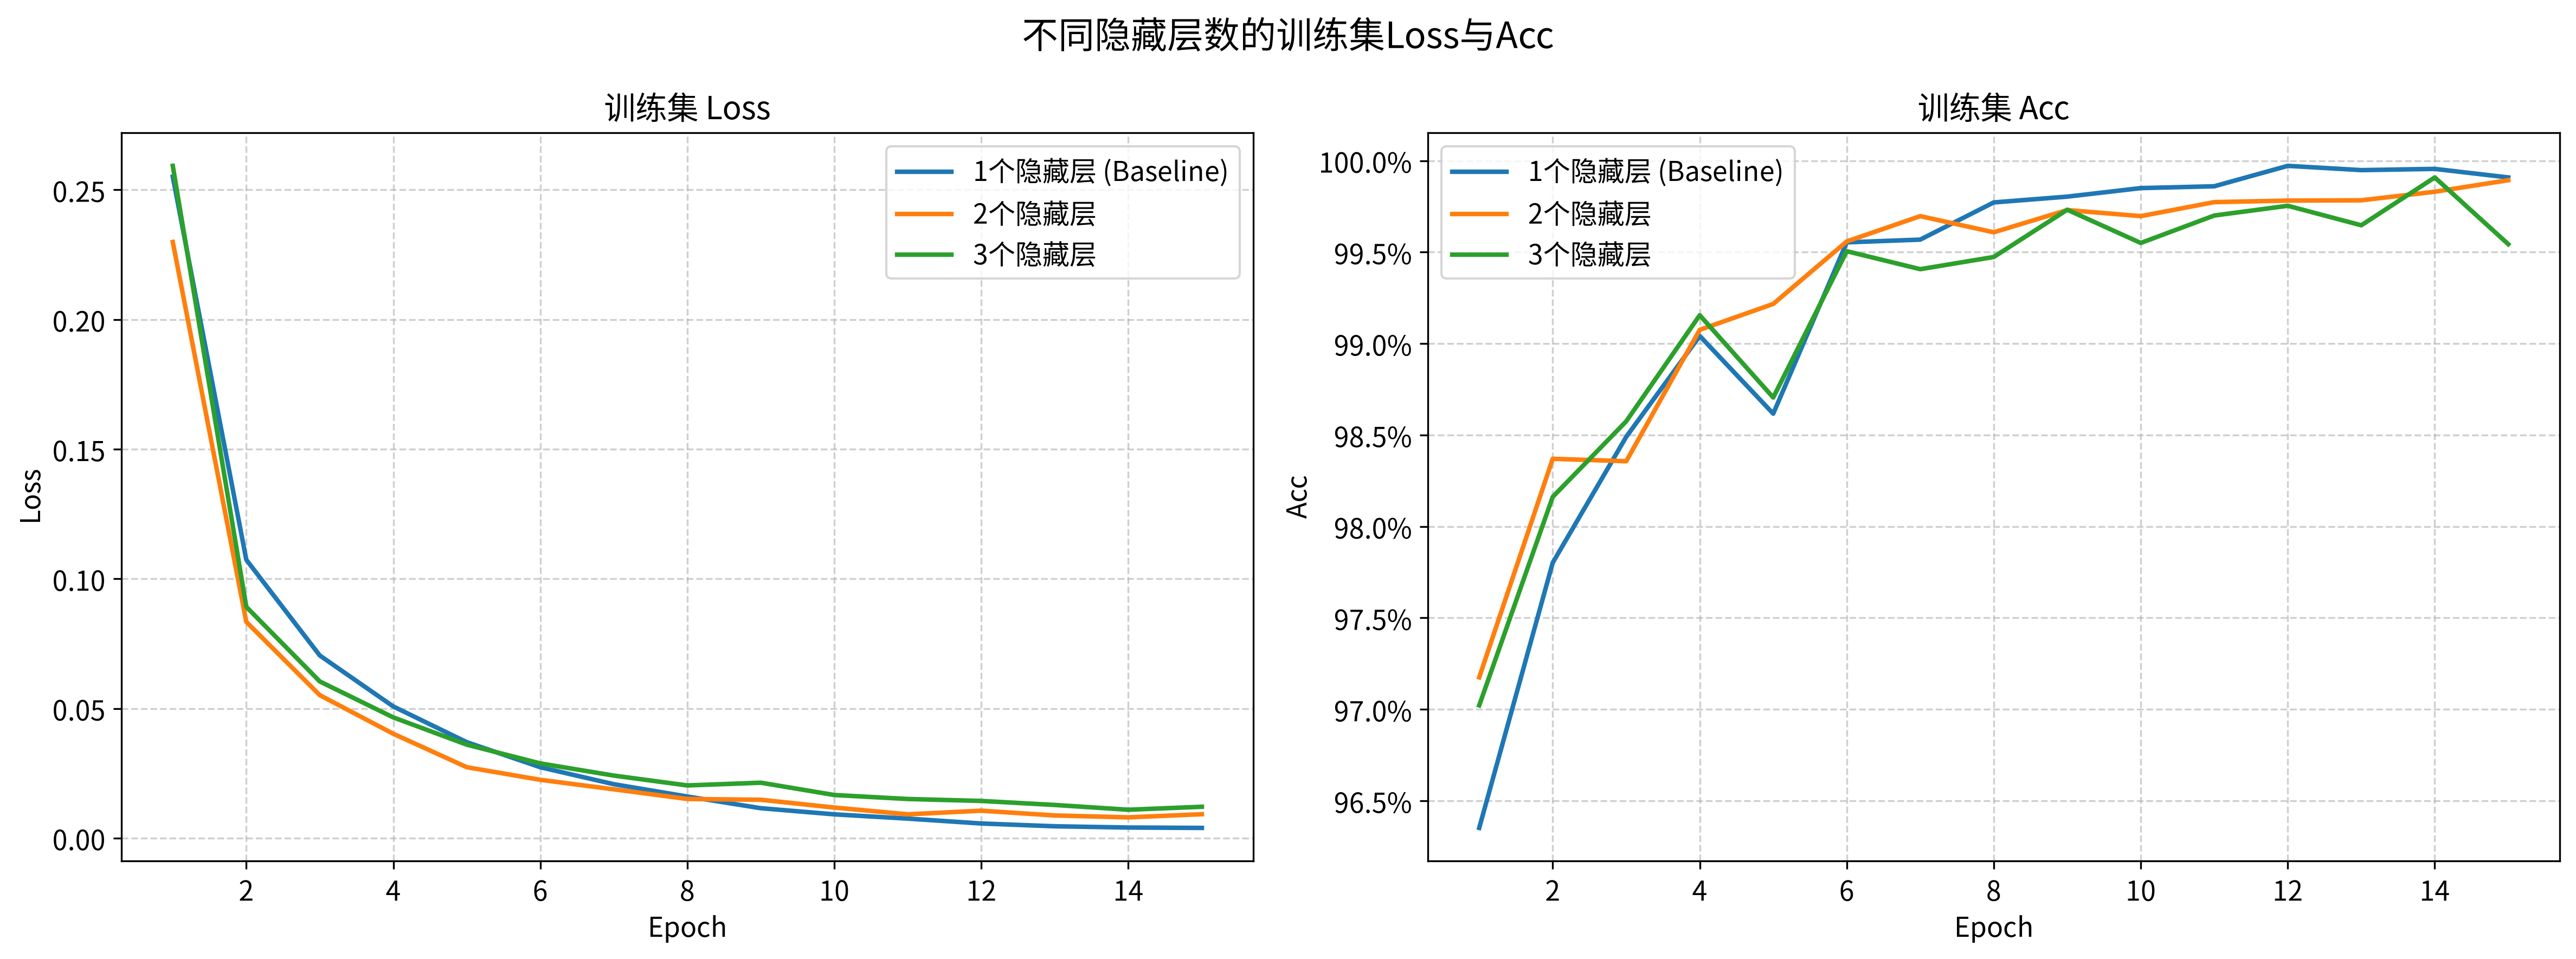

In [346]:
compare_data = {
    '1个隐藏层 (Baseline)': train_result_df,
    '2个隐藏层': train_result_df1,
    '3个隐藏层': train_result_df2
}
plot_multiple_models_train_result(compare_data, title="不同隐藏层数的训练集Loss与Acc")

##### 2.2 隐藏层神经元(单元)数
（1）修改网络结构如下：创建模型时，隐藏层单元数需要自己定义，隐藏层数保持为1

In [347]:
# 可调整隐藏层单元数的网络结构
class HiddenNumNet(nn.Module):
    def __init__(self, hidden_num):
        super().__init__()
        self.fc1 = nn.Linear(784, hidden_num) # 输入层 784 -> 隐藏层 hidden_num
        self.out = nn.Linear(hidden_num, 10) # 隐藏层 hidden_num -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

（2）将隐藏层单元数调整为64

In [348]:
model = HiddenNumNet(hidden_num = 64) # 将隐藏层单元数调整为64
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.367799,93.18%
2/15,0.214730,94.94%
3/15,0.165663,95.83%
4/15,0.134972,96.68%
5/15,0.113500,97.17%
6/15,0.098335,97.54%
7/15,0.086424,97.92%
8/15,0.077128,98.09%
9/15,0.069525,98.21%
10/15,0.062633,98.43%


In [349]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0903
测试集Acc: 97.45%  (9745/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0000,0.0000,0.0003,0.0000,0.0000,0.0000,0.9997,0.0000,0.0000
1,2,0.0000,0.0000,0.9998,0.0000,0.0000,0.0000,0.0000,0.0000,0.0001,0.0000
2,1,0.0000,0.9973,0.0006,0.0000,0.0000,0.0000,0.0001,0.0010,0.0010,0.0000
3,0,0.9999,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,4,0.0001,0.0000,0.0000,0.0000,0.9868,0.0000,0.0000,0.0004,0.0000,0.0126
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9996,3,0.0000,0.0000,0.0002,0.9997,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000
9997,4,0.0000,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0000,0.0000,0.0001
9998,5,0.0000,0.0000,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0001,0.0000


（3）将隐藏层单元数调整为32

In [350]:
model = HiddenNumNet(hidden_num = 32) # 将隐藏层单元数调整为32
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.421958,91.94%
2/15,0.261469,93.23%
3/15,0.221468,94.06%
4/15,0.192274,95.07%
5/15,0.170257,95.39%
6/15,0.154437,95.86%
7/15,0.141983,96.20%
8/15,0.131905,96.51%
9/15,0.122979,96.70%
10/15,0.115093,96.78%


In [351]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.1266
测试集Acc: 96.29%  (9629/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0000,0.0001,0.0071,0.0000,0.0000,0.0000,0.9927,0.0000,0.0001
1,2,0.0001,0.0050,0.9947,0.0001,0.0000,0.0001,0.0000,0.0000,0.0000,0.0000
2,1,0.0000,0.9937,0.0036,0.0003,0.0000,0.0002,0.0003,0.0010,0.0009,0.0000
3,0,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
4,4,0.0001,0.0000,0.0000,0.0000,0.9911,0.0000,0.0010,0.0000,0.0000,0.0077
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9996,3,0.0000,0.0000,0.0000,0.9999,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
9997,4,0.0000,0.0000,0.0000,0.0000,0.9966,0.0000,0.0000,0.0000,0.0000,0.0034
9998,5,0.0000,0.0000,0.0000,0.0000,0.0000,0.9995,0.0000,0.0000,0.0005,0.0000


（4）将隐藏层单元数调整为784

In [352]:
model = HiddenNumNet(hidden_num = 784) # 将隐藏层单元数调整为784
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 128)
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.237673,96.80%
2/15,0.094574,98.16%
3/15,0.061472,98.67%
4/15,0.043740,99.14%
5/15,0.030565,98.62%
6/15,0.022114,99.63%
7/15,0.016868,99.41%
8/15,0.012456,99.73%
9/15,0.009571,99.81%
10/15,0.007310,99.92%


In [353]:
test_result_df3 = evaluate_model(model, batch=128)
test_result_df3.round(4)

测试集loss: 0.0693
测试集Acc: 98.43%  (9843/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9999,0.0,0.0,0.0,0.0,0.0001
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（5）将隐藏层单元数调整为1024

In [354]:
model = HiddenNumNet(hidden_num = 1024) # 将隐藏层单元数调整为1024
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df4 = train_model(model, epochs=15, batch = 128)
train_result_df4.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.232563,97.03%
2/15,0.090214,98.27%
3/15,0.057989,98.82%
4/15,0.040375,99.21%
5/15,0.027809,98.74%
6/15,0.020212,99.73%
7/15,0.015479,99.71%
8/15,0.011860,99.83%
9/15,0.008953,99.82%
10/15,0.006802,99.93%


In [355]:
test_result_df4 = evaluate_model(model, batch=128)
test_result_df4.round(4)

测试集loss: 0.0851
测试集Acc: 98.30%  (9830/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0,0.0000
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,0.9997,0.0,0.0,0.0,0.0,0.0,0.0003
9997,4,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0000,0.0,1.0,0.0,0.0,0.0,0.0000


（6）对比结果可视化

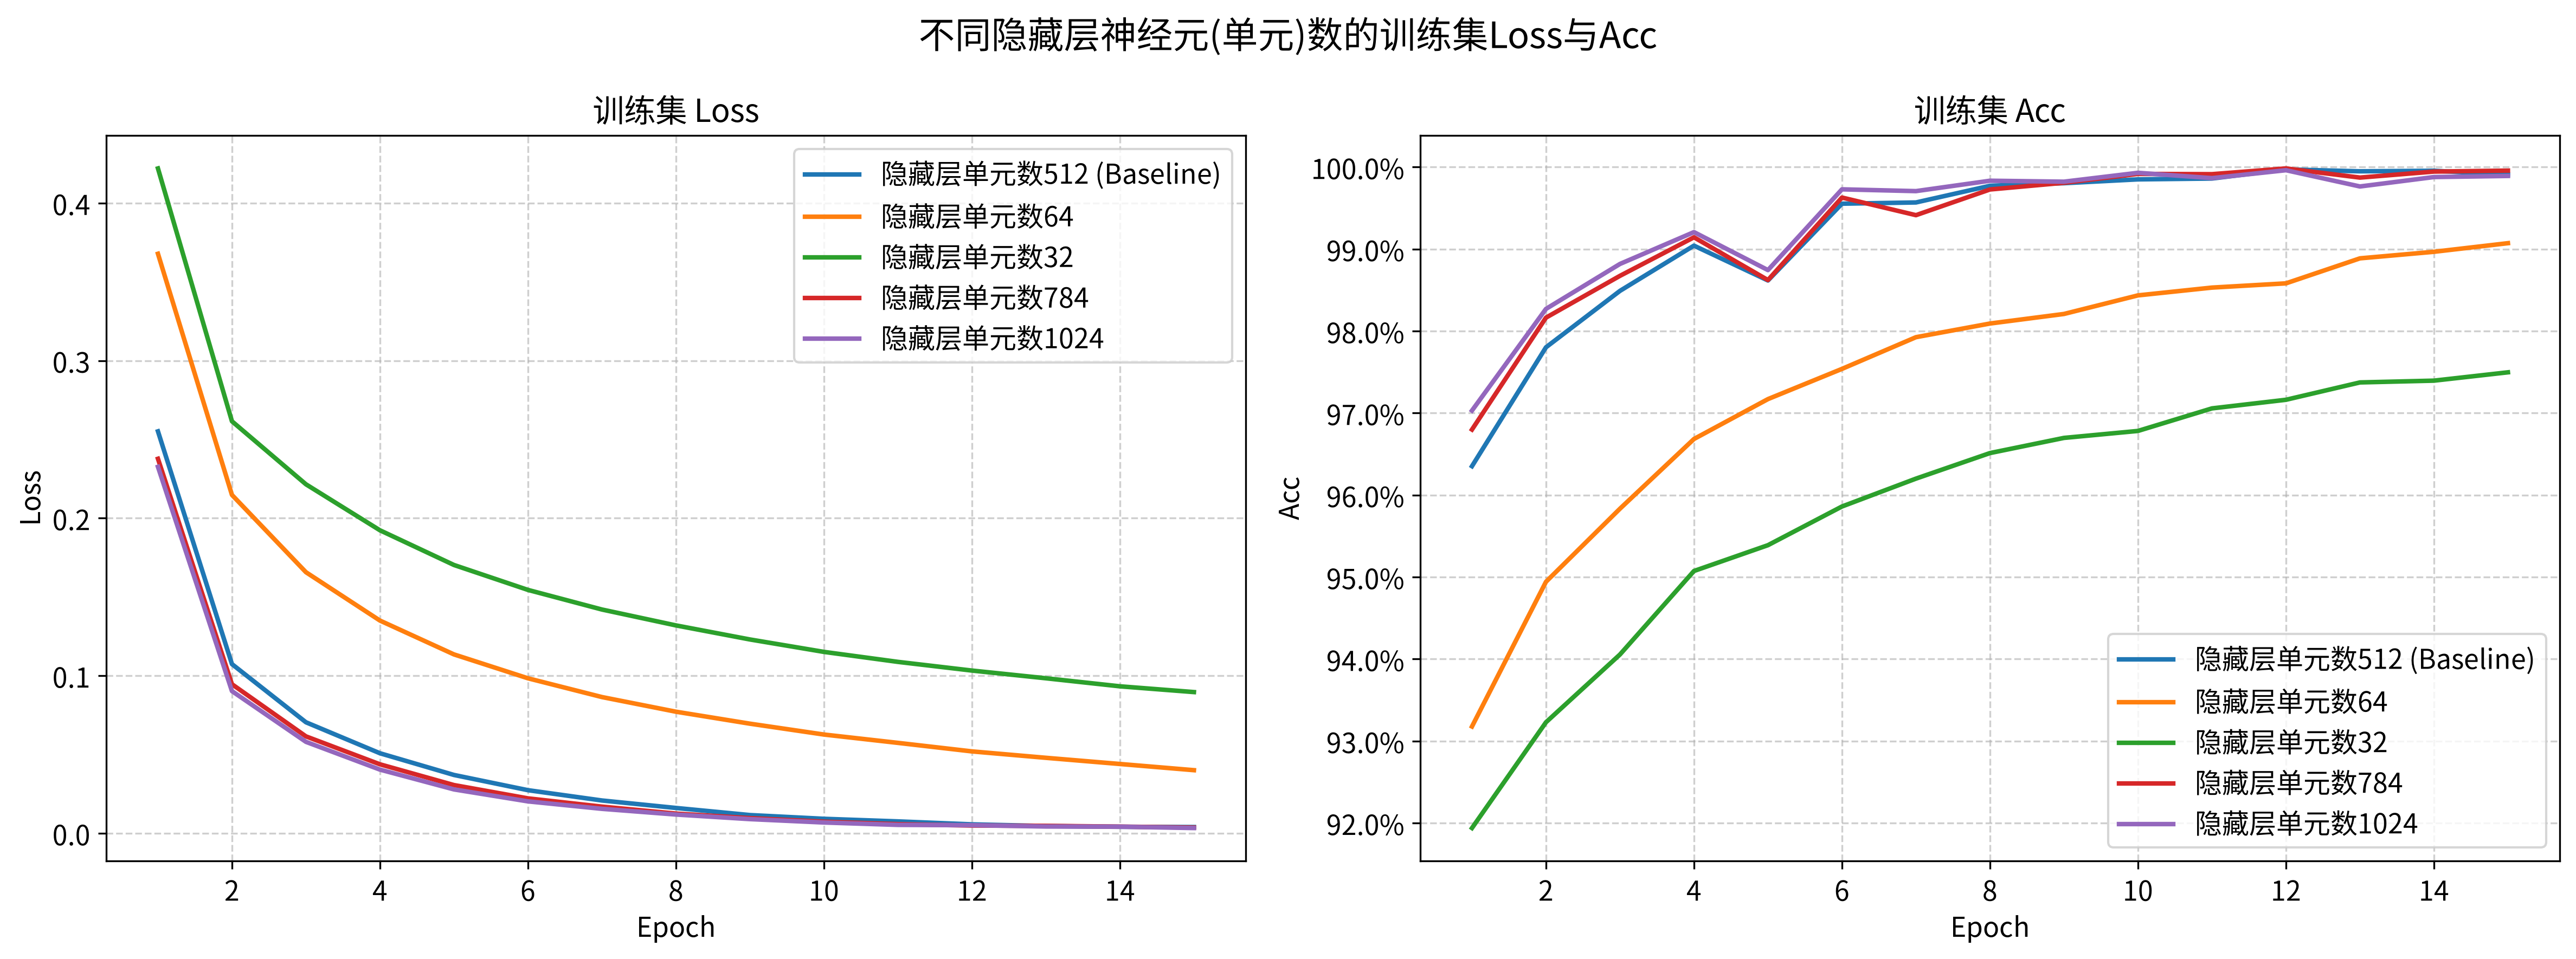

In [356]:
compare_data = {
    '隐藏层单元数512 (Baseline)': train_result_df,
    '隐藏层单元数64': train_result_df1,
    '隐藏层单元数32': train_result_df2,
    '隐藏层单元数784': train_result_df3,
    '隐藏层单元数1024': train_result_df4
}
plot_multiple_models_train_result(compare_data, title="不同隐藏层神经元(单元)数的训练集Loss与Acc")

##### 2.3 训练轮次epoch与批次大小batch
（1）调大epoch为25

In [357]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=25, batch = 128) # 调大epoch为25
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/25,0.249525,96.48%
2/25,0.105807,97.84%
3/25,0.069850,98.53%
4/25,0.050443,99.04%
5/25,0.036575,99.00%
6/25,0.026998,99.57%
7/25,0.020469,99.67%
8/25,0.015764,99.67%
9/25,0.011197,99.79%
10/25,0.009099,99.91%


In [358]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0913
测试集Acc: 98.20%  (9820/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（2）调小epoch为10

In [359]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=10, batch = 128) # 调小epoch为10
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/10,0.253476,96.41%
2/10,0.107814,97.91%
3/10,0.071111,98.46%
4/10,0.051557,99.00%
5/10,0.037349,98.96%
6/10,0.028265,99.56%
7/10,0.021302,99.62%
8/10,0.016569,99.69%
9/10,0.012170,99.85%
10/10,0.009886,99.87%


In [360]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.0644
测试集Acc: 98.07%  (9807/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9997,0.0,0.0,0.0,0.0,0.0003
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（3）调大batch为512

In [361]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 512) # 调大batch为512
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.389042,93.96%
2/15,0.173626,94.89%
3/15,0.127261,96.17%
4/15,0.097266,97.15%
5/15,0.078550,94.43%
6/15,0.064442,97.81%
7/15,0.052842,98.37%
8/15,0.044087,97.82%
9/15,0.036001,99.15%
10/15,0.030383,98.99%


In [362]:
test_result_df3 = evaluate_model(model, batch=512)
test_result_df3.round(4)

测试集loss: 0.1074
测试集Acc: 96.96%  (9696/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,1.0000,0.0000,0.0000
1,2,0.0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
2,1,0.0,0.9997,0.0001,0.0000,0.0000,0.0000,0.0,0.0001,0.0001,0.0000
3,0,1.0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
4,4,0.0,0.0000,0.0000,0.0000,0.9955,0.0000,0.0,0.0000,0.0000,0.0045
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0000,1.0000,0.0000,0.0000,0.0000,0.0,0.0000,0.0000,0.0000
9996,3,0.0,0.0000,0.0001,0.9982,0.0000,0.0003,0.0,0.0000,0.0000,0.0015
9997,4,0.0,0.0000,0.0000,0.0000,1.0000,0.0000,0.0,0.0000,0.0000,0.0000
9998,5,0.0,0.0000,0.0000,0.0000,0.0000,1.0000,0.0,0.0000,0.0000,0.0000


（4）调小batch为32

In [363]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df4 = train_model(model, epochs=15, batch = 32) # 调小batch为32
train_result_df4.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.193535,97.42%
2/15,0.079625,98.55%
3/15,0.052011,98.78%
4/15,0.037610,99.30%
5/15,0.026911,99.22%
6/15,0.020440,99.68%
7/15,0.015482,99.66%
8/15,0.013609,99.81%
9/15,0.010386,99.78%
10/15,0.009259,99.76%


In [364]:
test_result_df4 = evaluate_model(model, batch=32)
test_result_df4.round(4)

测试集loss: 0.1056
测试集Acc: 98.22%  (9822/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9996,3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
9997,4,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
9998,5,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0


（5）对比结果可视化

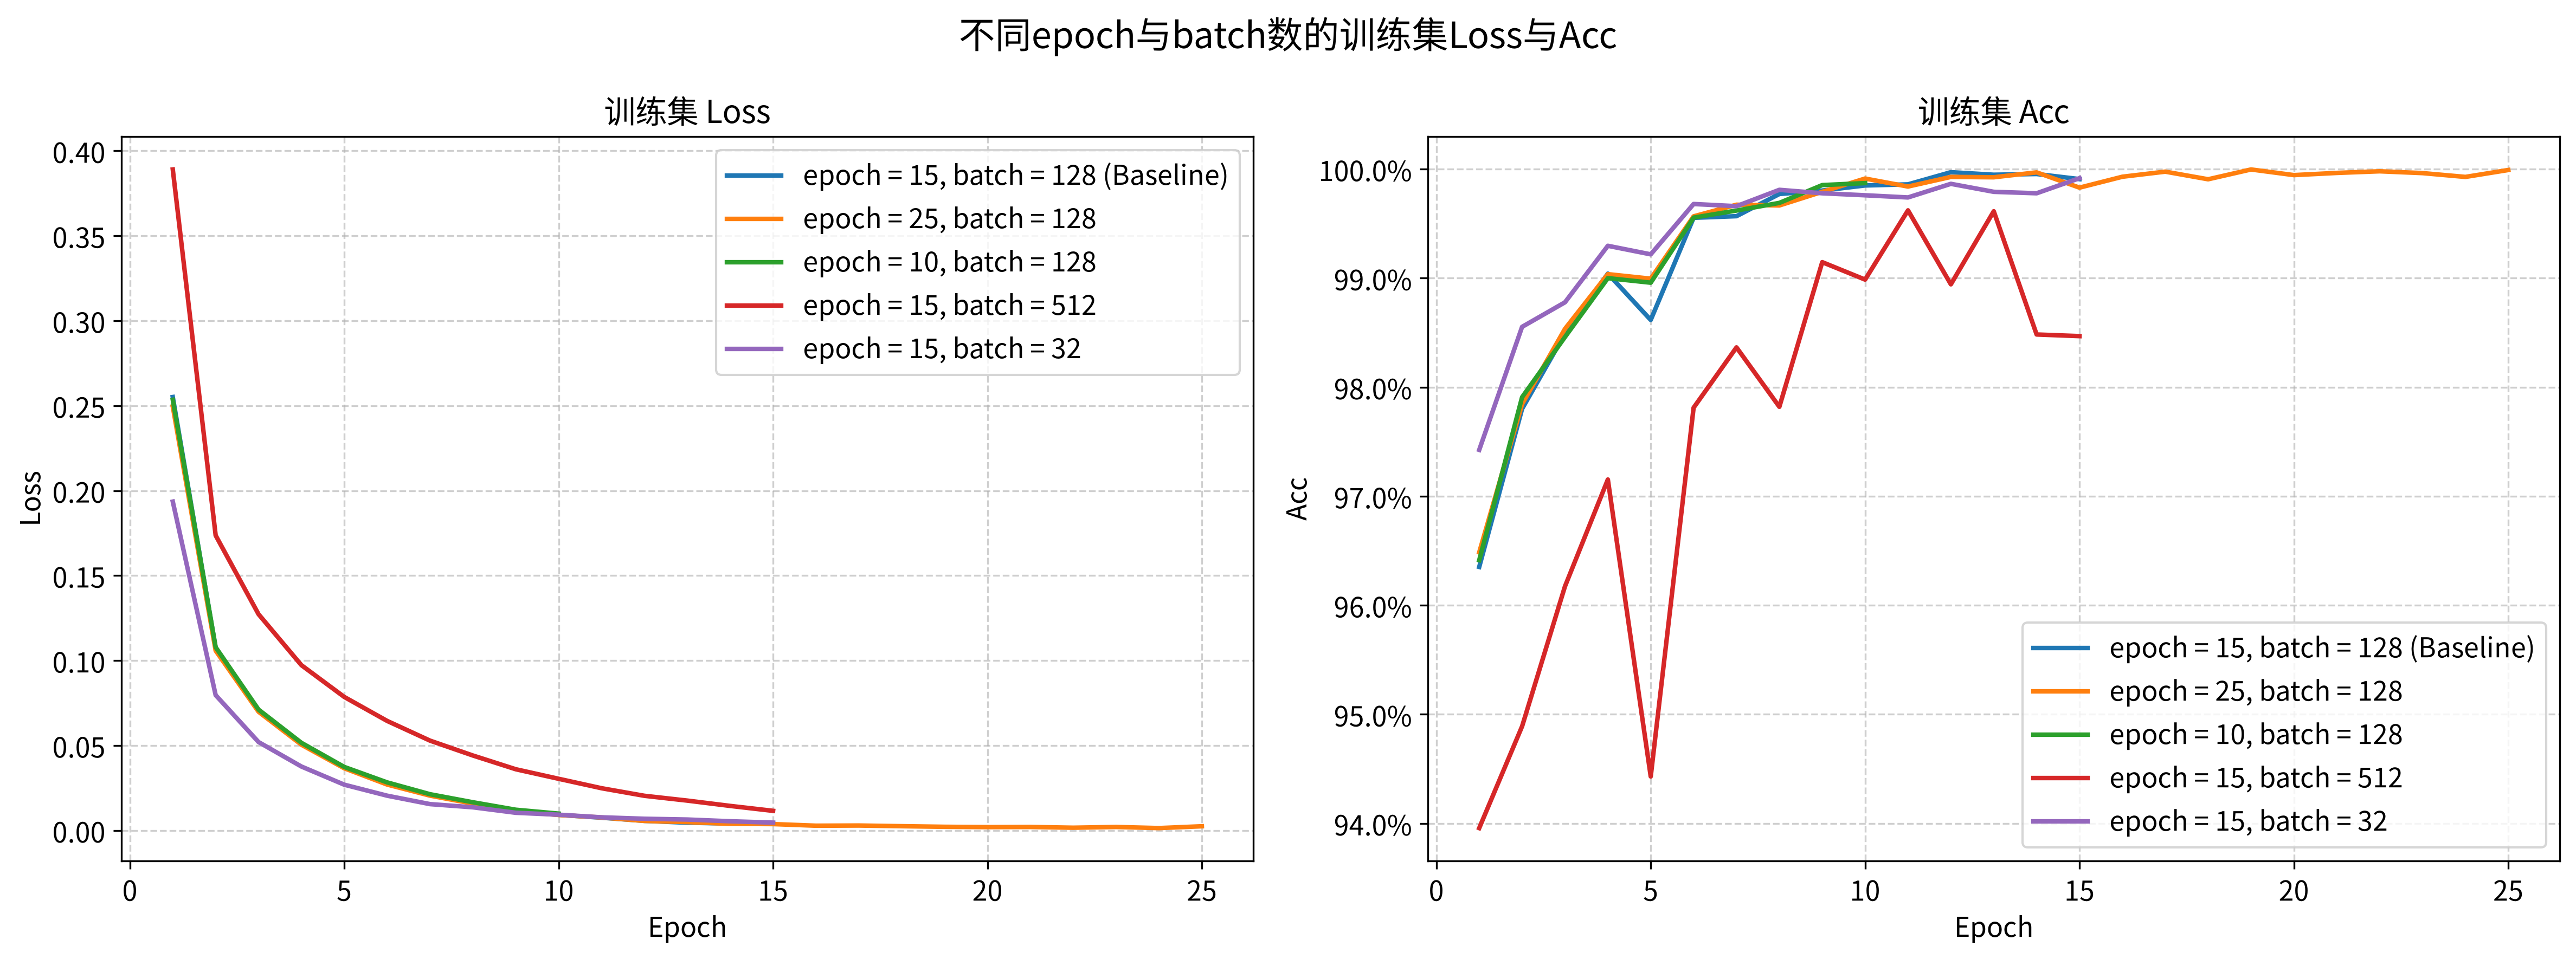

In [365]:
compare_data = {
    'epoch = 15, batch = 128 (Baseline)': train_result_df,
    'epoch = 25, batch = 128': train_result_df1,
    'epoch = 10, batch = 128': train_result_df2,
    'epoch = 15, batch = 512': train_result_df3,
    'epoch = 15, batch = 32': train_result_df4
}
plot_multiple_models_train_result(compare_data, title="不同epoch与batch数的训练集Loss与Acc")

##### 2.4 调整Dropout失活比例
（1）定义可调整失活比例的网络结构

In [366]:
# 可调整Dropout失活比例的网络结构
class DropoutNet(nn.Module):
    def __init__(self, dropout):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(p=dropout) # 随机丢弃p比例数量的神经元

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.dropout(x)  # 在激活函数之后，输出层之前，应用Dropout
        x = self.out(x)  # 直接输出线性结果
        return x

（2）设置Dropout比例为0.2

In [367]:
model = DropoutNet(0.2) # 定义Dropout比例为0.2的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.267441,96.21%
2/15,0.120434,97.74%
3/15,0.083831,98.19%
4/15,0.063397,98.92%
5/15,0.049661,98.89%
6/15,0.039454,99.34%
7/15,0.033093,99.45%
8/15,0.027769,99.69%
9/15,0.022563,99.64%
10/15,0.020120,99.81%


In [368]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0695
测试集Acc: 98.23%  (9823/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9986,0.0,0.0,0.0,0.0,0.0014
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（3）设置Dropout比例为0.5

In [369]:
model = DropoutNet(0.5) # 定义Dropout比例为0.5的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df2 = train_model(model, epochs=15, batch = 128)
train_result_df2.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.309671,95.75%
2/15,0.153834,97.28%
3/15,0.116651,97.61%
4/15,0.096500,98.44%
5/15,0.080382,98.63%
6/15,0.073010,99.00%
7/15,0.065208,99.04%
8/15,0.058534,99.19%
9/15,0.051435,99.33%
10/15,0.050089,99.41%


In [370]:
test_result_df2 = evaluate_model(model, batch=128)
test_result_df2.round(4)

测试集loss: 0.0618
测试集Acc: 98.39%  (9839/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9995,0.0,0.0,0.0,0.0,0.0005
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（4）设置Dropout比例为0.7

In [371]:
model = DropoutNet(0.7) # 定义Dropout比例为0.7的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df3 = train_model(model, epochs=15, batch = 128)
train_result_df3.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.364156,94.77%
2/15,0.210141,96.47%
3/15,0.169210,97.11%
4/15,0.145897,97.65%
5/15,0.130870,97.99%
6/15,0.120575,98.24%
7/15,0.112150,98.46%
8/15,0.105874,98.55%
9/15,0.103455,98.63%
10/15,0.097113,98.86%


In [372]:
test_result_df3 = evaluate_model(model, batch=128)
test_result_df3.round(4)

测试集loss: 0.0674
测试集Acc: 98.15%  (9815/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0000,0.0,0.0000,0.0000,0.0000,0.0000,0.0,1.0,0.0,0.0000
1,2,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
2,1,0.0000,1.0,0.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
3,0,0.9999,0.0,0.0001,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
4,4,0.0000,0.0,0.0000,0.0000,0.9963,0.0000,0.0,0.0,0.0,0.0036
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0000,0.0,1.0000,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
9996,3,0.0000,0.0,0.0000,0.9996,0.0000,0.0004,0.0,0.0,0.0,0.0000
9997,4,0.0000,0.0,0.0000,0.0000,1.0000,0.0000,0.0,0.0,0.0,0.0000
9998,5,0.0000,0.0,0.0000,0.0000,0.0000,1.0000,0.0,0.0,0.0,0.0000


（5）对比结果可视化

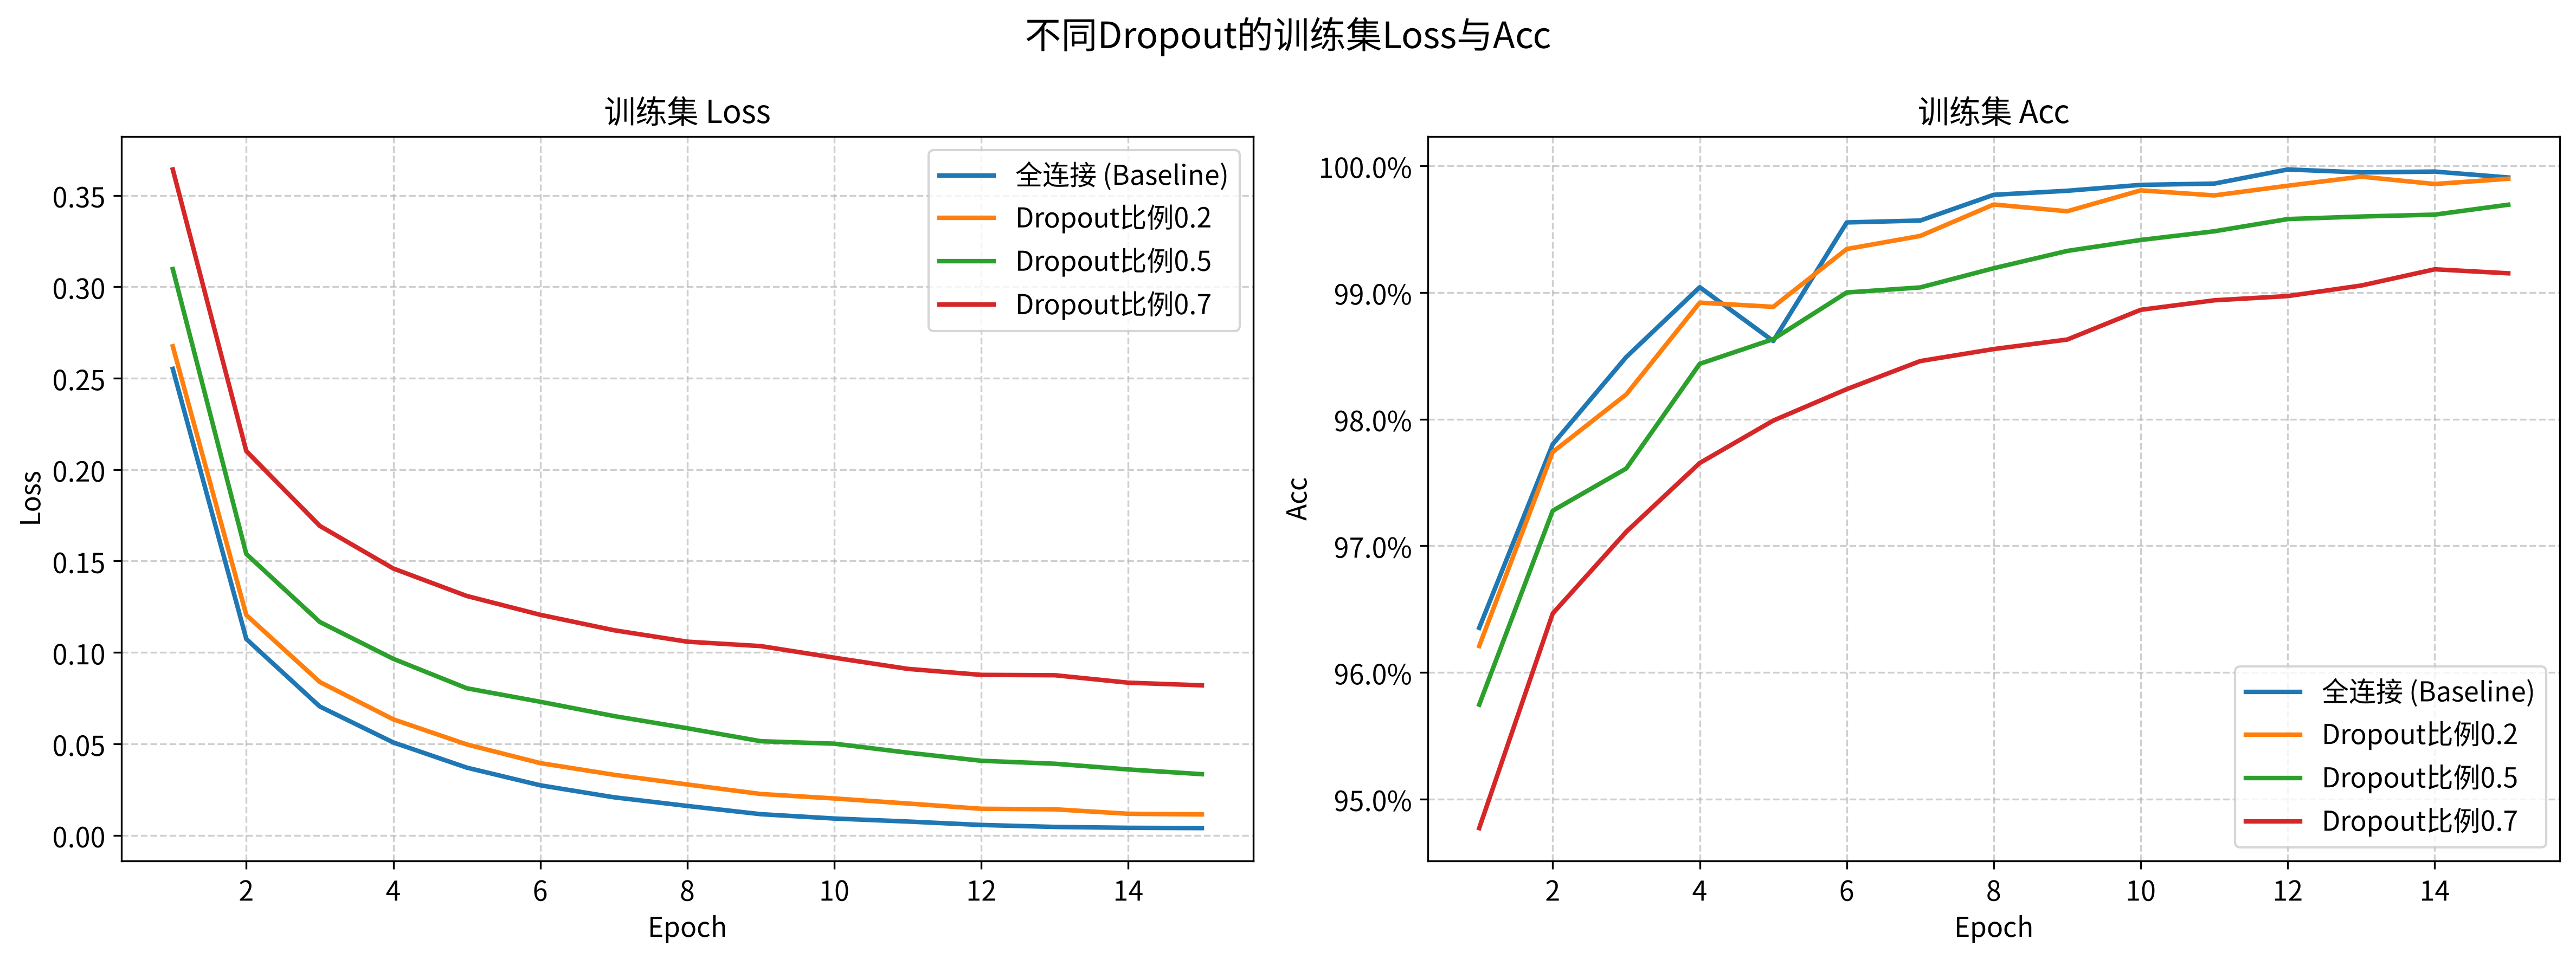

In [373]:
compare_data = {
    '全连接 (Baseline)': train_result_df,
    'Dropout比例0.2': train_result_df1,
    'Dropout比例0.5': train_result_df2,
    'Dropout比例0.7': train_result_df3
}
plot_multiple_models_train_result(compare_data, title="不同Dropout的训练集Loss与Acc")

##### 2.5 将loss函数改为MSE
（1）修改训练与评估函数，使训练时使用one-hot编码，适配MSE的loss函数

In [381]:
import torch.nn.functional as F # 将无序类别标签转为one-hot

def train_model_mse(model, epochs, batch):
    # 全数据集分 batch
    g = torch.Generator()
    g.manual_seed(42)  # 固定随机种子，保证 batch 划分可复现

    train_dataset = TensorDataset(x_train_tensor, y_train_tensor)
    train_dataloader = DataLoader(
        train_dataset, batch_size=batch, shuffle=True, generator=g
    )

    eval_dataloader = DataLoader(
        train_dataset, batch_size=batch, shuffle=False
    )

    loss_result = []

    for epoch in range(epochs):
        train_total_loss_sum = 0.0
        train_num = 0

        model.train()
        for batch_x, batch_y in train_dataloader:
            optimizer.zero_grad()
            preds_y = model(batch_x)

            # 把整数标签 (B,) 转成 one-hot (B,10) 再算 loss
            batch_y_one_hot = F.one_hot(batch_y, num_classes=10).float()
            loss_train = criterion(preds_y, batch_y_one_hot)

            loss_train.backward()
            optimizer.step()

            train_total_loss_sum += loss_train.item() * batch_y.size(0)
            train_num += batch_y.size(0)

        train_correct = 0
        eval_num = 0

        model.eval()
        with torch.no_grad():
            for batch_x, batch_y in eval_dataloader:
                train_preds = model(batch_x)
                predicted_classes = torch.argmax(train_preds, dim=1)
                train_correct += (predicted_classes == batch_y).sum().item()
                eval_num += batch_y.size(0)

        loss_result.append([
            f"{epoch + 1}/{epochs}",
            train_total_loss_sum / train_num,
            train_correct / eval_num
        ])

    result_df = pd.DataFrame(loss_result, columns=['Epoch', 'Loss', 'Acc'])
    return result_df

# 评估函数
def evaluate_model_mse(model, batch):
    model.eval()  # 切换到测试状态

    test_correct = 0
    test_num = 0
    test_total_loss_sum = 0.0

    test_result = []
    test_probs = []

    test_dataset = TensorDataset(x_test_tensor, y_test_tensor)
    test_dataloader = DataLoader(test_dataset, batch_size=batch, shuffle=False)

    with torch.no_grad():
        for batch_x, batch_y in test_dataloader:
            test_preds = model(batch_x)

            # 标签转 one-hot 后再算 MSE
            batch_y_one_hot = F.one_hot(batch_y, num_classes=10).float()
            loss = criterion(test_preds, batch_y_one_hot)

            test_total_loss_sum += loss.item() * batch_y.size(0)
            test_num += batch_y.size(0)

            predicted_classes = torch.argmax(test_preds, dim=1)
            test_correct += (predicted_classes == batch_y).sum().item()

            test_result += predicted_classes.tolist()
            test_probs += torch.softmax(test_preds, dim=1).tolist()

    avg_test_loss = test_total_loss_sum / test_num
    accuracy = test_correct / test_num

    print(f"测试集loss: {avg_test_loss:.4f}")
    print(f"测试集Acc: {accuracy * 100:.2f}%  ({test_correct}/{test_num})")

    result_df = pd.DataFrame(test_result, columns=['Predict'])
    prob_columns = [f'Prob_{i}' for i in range(10)]
    prob_df = pd.DataFrame(test_probs, columns=prob_columns)
    result_df = pd.concat([result_df, prob_df], axis=1)

    return result_df

（2）修改loss函数为MSE

In [383]:
model = Net() # 定义 激活函数为tanh 的模型
criterion = nn.MSELoss() # 损失函数（MSE）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model_mse(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.033230,95.51%
2/15,0.012000,97.17%
3/15,0.009626,97.86%
4/15,0.008103,98.23%
5/15,0.007138,98.68%
6/15,0.006427,98.91%
7/15,0.005893,99.07%
8/15,0.005478,99.19%
9/15,0.005152,99.32%
10/15,0.004852,99.40%


In [384]:
test_result_df1 = evaluate_model_mse(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0071
测试集Acc: 98.04%  (9804/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0884,0.0870,0.0883,0.0886,0.0894,0.0882,0.0876,0.2055,0.0905,0.0865
1,2,0.0836,0.0796,0.2472,0.0808,0.0861,0.0853,0.0804,0.0844,0.0894,0.0832
2,1,0.0850,0.2321,0.0825,0.0860,0.0855,0.0856,0.0858,0.0827,0.0892,0.0854
3,0,0.2284,0.0856,0.0881,0.0844,0.0862,0.0849,0.0860,0.0854,0.0866,0.0844
4,4,0.0821,0.0833,0.0805,0.0822,0.2623,0.0830,0.0788,0.0844,0.0837,0.0798
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0818,0.0800,0.2444,0.0821,0.0857,0.0839,0.0839,0.0831,0.0948,0.0803
9996,3,0.0891,0.0877,0.0882,0.1896,0.0882,0.0896,0.0897,0.0880,0.0986,0.0912
9997,4,0.0888,0.0857,0.0847,0.0855,0.2347,0.0843,0.0851,0.0852,0.0883,0.0778
9998,5,0.0784,0.0834,0.0791,0.0800,0.0797,0.2606,0.0817,0.0842,0.0881,0.0848


（3）对比结果可视化

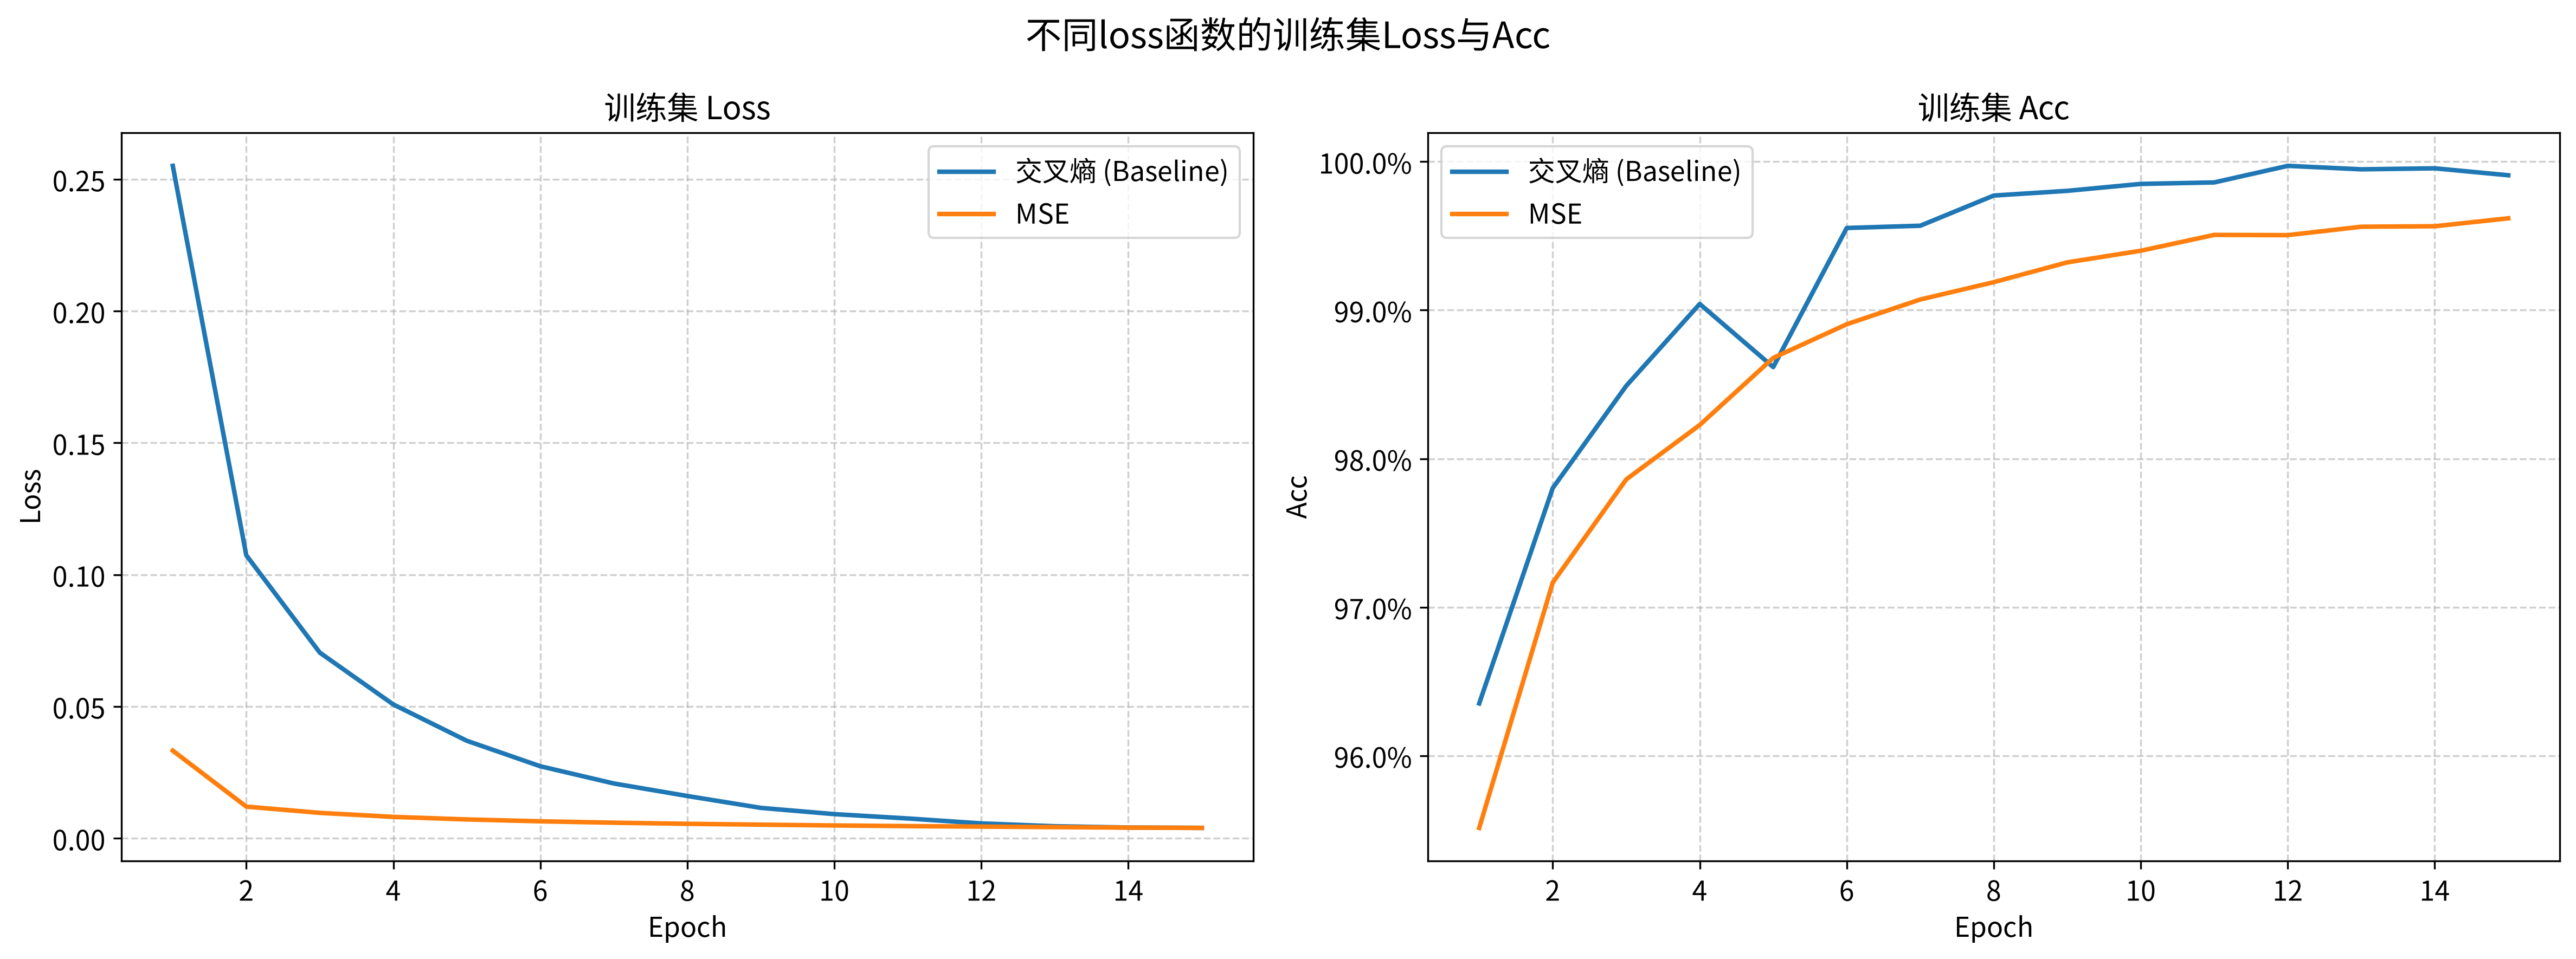

In [385]:
compare_data = {
    '交叉熵 (Baseline)': train_result_df,
    'MSE': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同loss函数的训练集Loss与Acc")

##### 2.6 激活函数改为tanh
（1）调整网络结构，将激活函数修改为tanh，训练并评估模型

In [374]:
# 修改网络结构，将激活函数调整为tanh
class TanhNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.tanh = nn.Tanh()

    def forward(self, x):
        x = self.tanh(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

In [375]:
model = TanhNet() # 定义 激活函数为tanh 的模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.313747,94.37%
2/15,0.166757,96.29%
3/15,0.112684,97.20%
4/15,0.081531,98.22%
5/15,0.061854,98.18%
6/15,0.046479,99.09%
7/15,0.035902,99.16%
8/15,0.027410,99.58%
9/15,0.020709,99.66%
10/15,0.015729,99.77%


In [376]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0715
测试集Acc: 98.12%  (9812/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0000,0.9999,0.0000,0.0,0.0,0.0,0.0001
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0000,0.0000,0.0000,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,0.9999,0.0000,0.0001,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0000,1.0000,0.0000,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0000,0.0000,1.0000,0.0,0.0,0.0,0.0000


（2）对比结果可视化

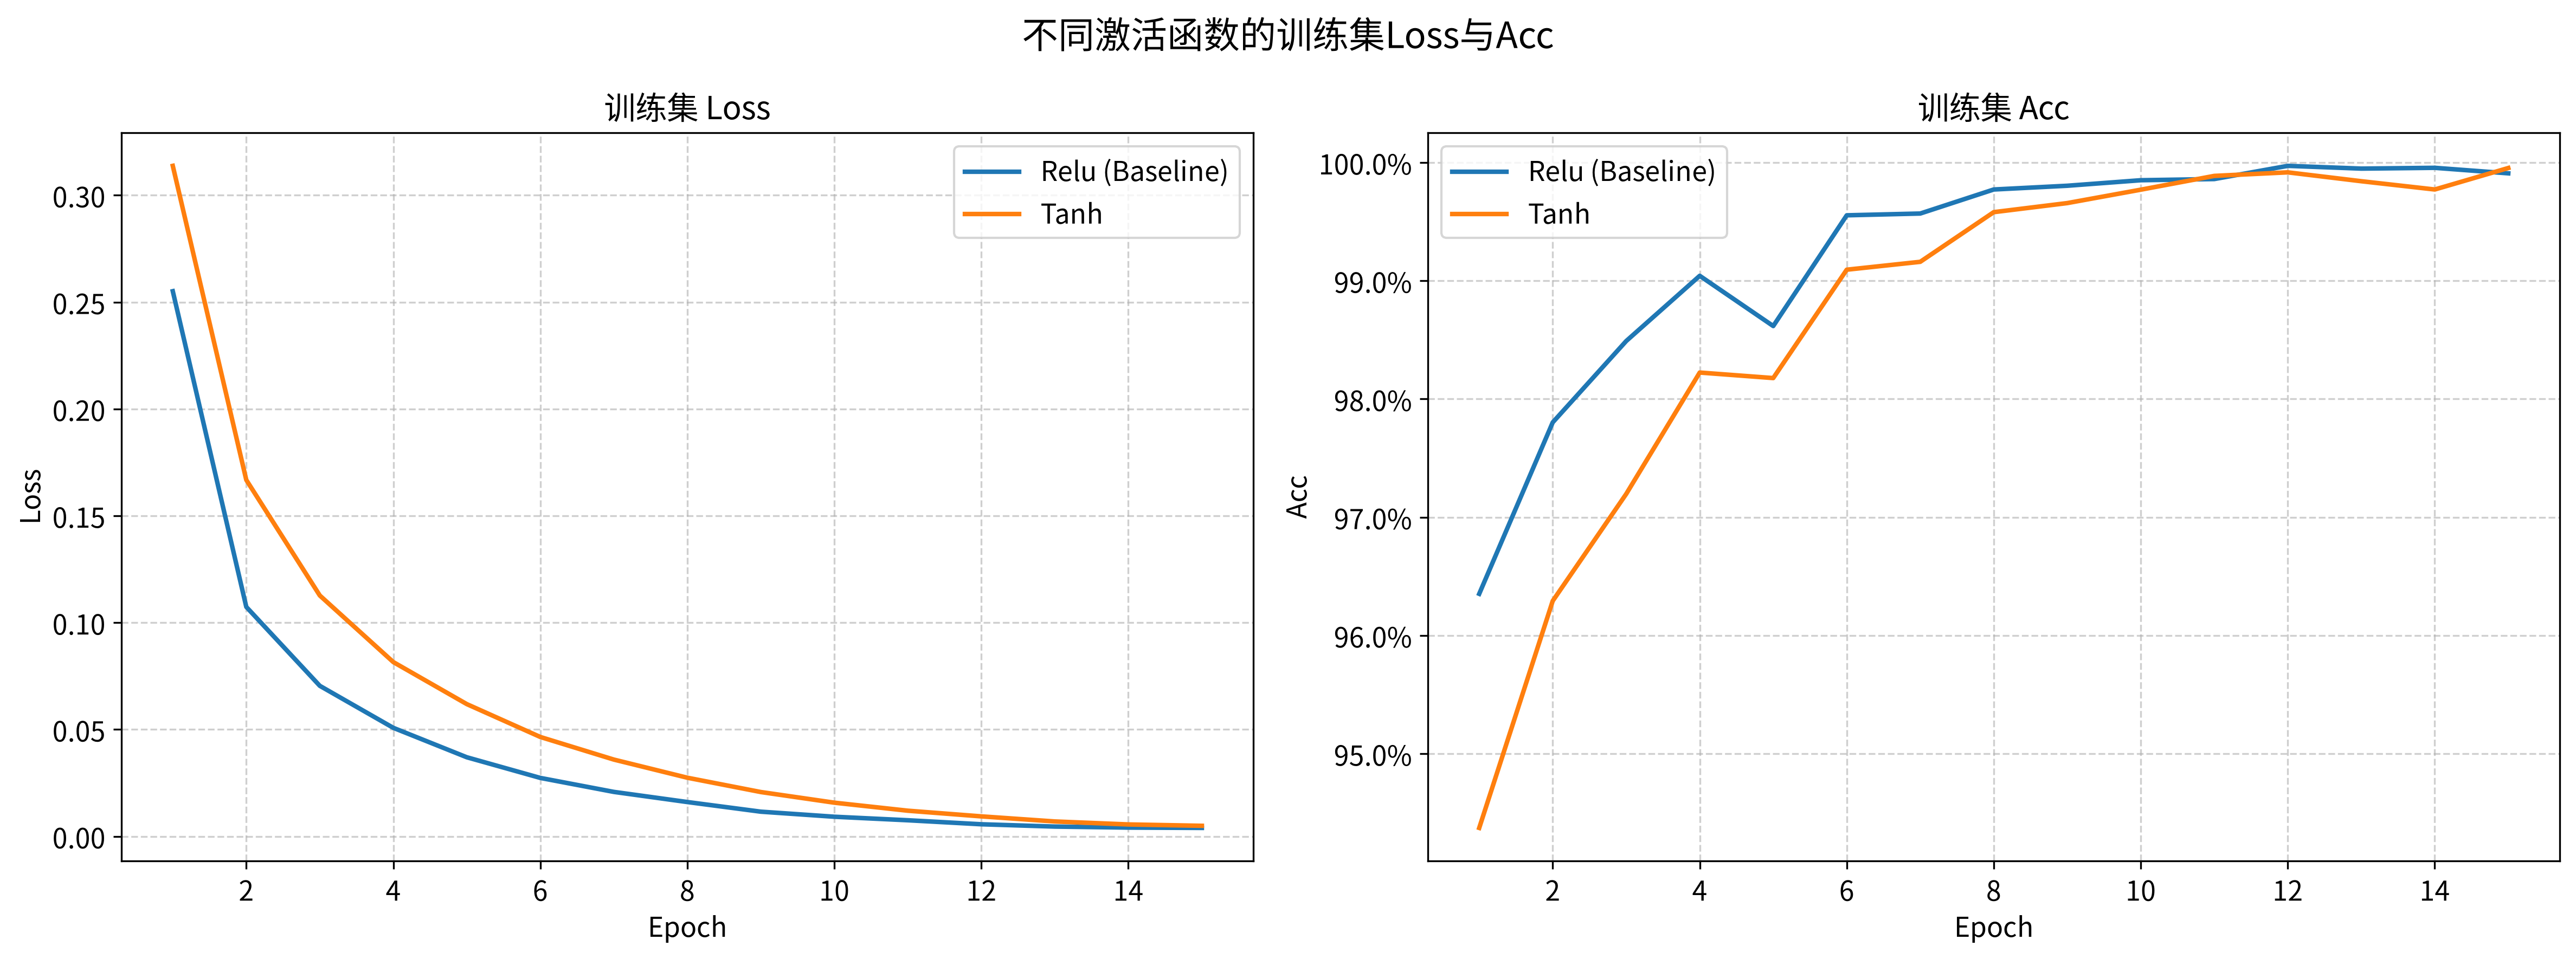

In [377]:
compare_data = {
    'Relu (Baseline)': train_result_df,
    'Tanh': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同激活函数的训练集Loss与Acc")

##### 2.7 将优化器改为Adam
（1）将优化器调整为Adam后，训练并评估模型

In [378]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.RMSprop(model.parameters(), lr = 0.001) # 调整为Adam优化器

train_result_df1 = train_model(model, epochs=15, batch = 128)
train_result_df1.style.format({'Acc': '{:.2%}'}).hide(axis = 'index')

Epoch,Loss,Acc
1/15,0.249711,96.41%
2/15,0.106962,97.91%
3/15,0.070476,98.45%
4/15,0.050515,99.05%
5/15,0.036075,99.04%
6/15,0.026740,99.54%
7/15,0.020392,99.64%
8/15,0.015818,99.78%
9/15,0.011485,99.85%
10/15,0.008961,99.86%


In [379]:
test_result_df1 = evaluate_model(model, batch=128)
test_result_df1.round(4)

测试集loss: 0.0823
测试集Acc: 98.09%  (9809/10000)


,Predict,Prob_0,Prob_1,Prob_2,Prob_3,Prob_4,Prob_5,Prob_6,Prob_7,Prob_8,Prob_9
0,7,0.0,0.0,0.0,0.0,0.0000,0.0,0.0,1.0,0.0,0.0000
1,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
2,1,0.0,1.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
3,0,1.0,0.0,0.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
4,4,0.0,0.0,0.0,0.0,0.9998,0.0,0.0,0.0,0.0,0.0002
...,...,...,...,...,...,...,...,...,...,...,...
9995,2,0.0,0.0,1.0,0.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9996,3,0.0,0.0,0.0,1.0,0.0000,0.0,0.0,0.0,0.0,0.0000
9997,4,0.0,0.0,0.0,0.0,1.0000,0.0,0.0,0.0,0.0,0.0000
9998,5,0.0,0.0,0.0,0.0,0.0000,1.0,0.0,0.0,0.0,0.0000


（2）对比结果可视化

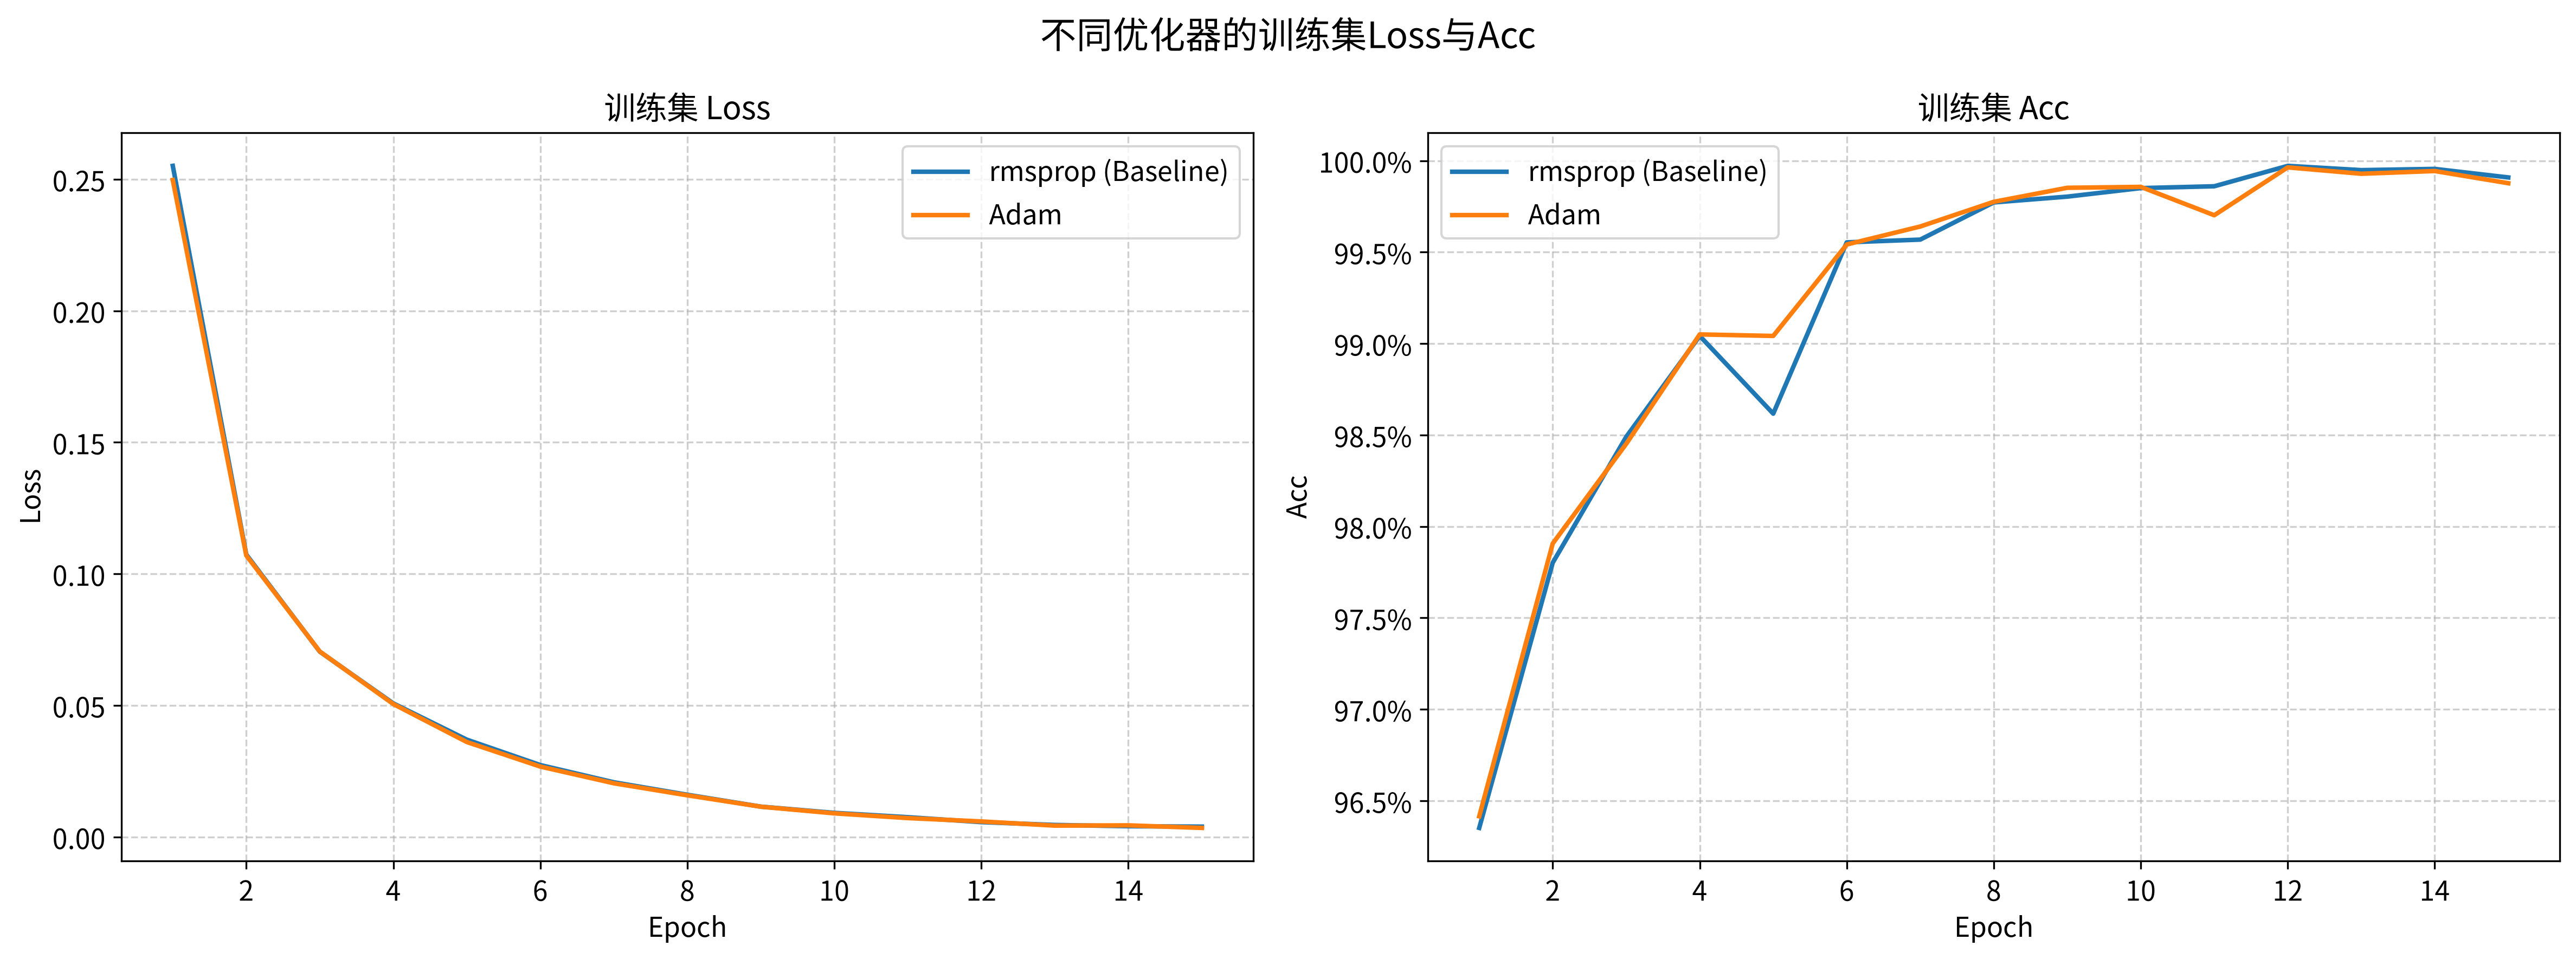

In [380]:
compare_data = {
    'rmsprop (Baseline)': train_result_df,
    'Adam': train_result_df1
}
plot_multiple_models_train_result(compare_data, title="不同优化器的训练集Loss与Acc")